# Learning from Data

First module of the learning path: what machine learning is, the three types of learning, the vocabulary and notation, the workflow of an ML project and the Python setup.

The notes are a compendium written in my own words from several sources, and every figure is drawn with code. Read each section, run the demo and solve the exercises. Exercise cells contain only `# TODO` comments, so the notebook runs from top to bottom before you solve anything.

| Section | What you do here |
|---|---|
| 1. What machine learning is | Notes, 1 exercise |
| 2. The three types of learning | 4 demos, 4 exercises, 1 companion tutorial |
| 3. Terminology and notation | Iris as a matrix, 3 exercises |
| 4. Roadmap for an ML system | Baseline pipeline, 4 exercises |
| 5. Python setup | Version check, 2 exercises |
| 6. Self-check | 8 questions |

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
import sklearn

# Versions installed in this environment
installed = {"numpy": np, "scipy": scipy, "sklearn": sklearn,
             "matplotlib": matplotlib, "pandas": pd}

print("Python", sys.version.split()[0])
pd.DataFrame({"installed": {name: mod.__version__ for name, mod in installed.items()}})

Python 3.14.6


,installed
numpy,2.4.6
scipy,1.18.0
sklearn,1.9.0
matplotlib,3.11.0
pandas,3.0.3


## 1. What machine learning is

Machine learning is the part of AI where the program derives its rules from data. You do not write the rules by hand. You give an algorithm examples, it fits a model to them, and the model makes predictions on data it has not seen.

Products that already depend on it include spam filters, voice and text recognition, web search, movie recommendations, mobile check deposits and delivery time estimates. Research results include skin cancer detection from images and protein structure prediction.

### Exercise 1.1

Pick three products you used this week that rely on machine learning. For each one, write what the model receives as input and what it predicts.

**Your answer:**

## 2. The three types of machine learning

| Type | What the data looks like | What the model learns |
|---|---|---|
| Supervised | Inputs with known labels or target values | A mapping from inputs to labels |
| Unsupervised | Inputs only, no labels | Structure hidden in the data |
| Reinforcement | States, actions and a reward signal | Which actions maximize the total reward |

### 2.1 Supervised learning

The training data comes with the right answer attached. The algorithm models the relationship between inputs and labels, and the fitted model predicts labels for new inputs.

It splits in two by the kind of label:

- **Classification** predicts a discrete, unordered class label. Two classes is binary classification (spam or not spam). More than two is multiclass classification (which letter was handwritten). A classifier can only predict classes that appeared in its training data.
- **Regression** predicts a continuous value. The inputs are called *features* and the output is the *target variable*.

#### Demo: binary classification

Thirty training examples, 15 per class, each with two features $x_1$ and $x_2$. The model learns a decision boundary and uses it to classify a new point.

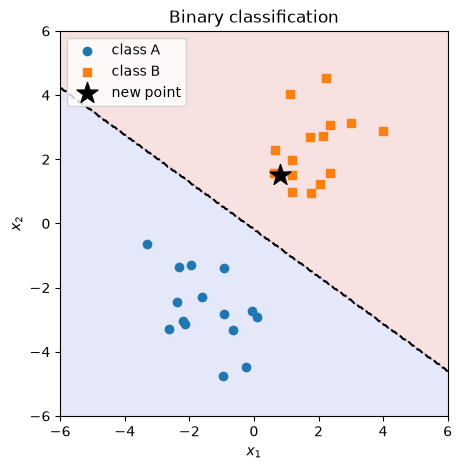

Classes per group: [15 15]
The new point is classified as: class B


In [2]:
from sklearn.datasets import make_blobs
from sklearn.linear_model import LogisticRegression

X_clf, y_clf = make_blobs(n_samples=30, centers=[[-2, -2], [2, 2]],
                          cluster_std=1.2, random_state=1)
clf = LogisticRegression().fit(X_clf, y_clf)

new_point = np.array([[0.8, 1.5]])
predicted = clf.predict(new_point)[0]

# Shade the region the model assigns to each class
xx, yy = np.meshgrid(np.linspace(-6, 6, 300), np.linspace(-6, 6, 300))
zz = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(5, 5))
ax.contourf(xx, yy, zz, alpha=0.15, cmap="coolwarm")
ax.contour(xx, yy, zz, levels=[0.5], colors="k", linestyles="--")
ax.scatter(*X_clf[y_clf == 0].T, marker="o", label="class A")
ax.scatter(*X_clf[y_clf == 1].T, marker="s", label="class B")
ax.scatter(*new_point.T, marker="*", s=250, c="k", label="new point")
ax.set(xlabel="$x_1$", ylabel="$x_2$", title="Binary classification")
ax.legend()
plt.show()

print("Classes per group:", np.bincount(y_clf))
print("The new point is classified as:", "class A" if predicted == 0 else "class B")

#### Demo: regression

The example predicts a test score from the hours studied. The data is synthetic: it comes from a line plus random noise, so the "true" intercept and slope are known (400 and 30).

Linear regression fits the line that minimizes the average squared distance between the points and the line.

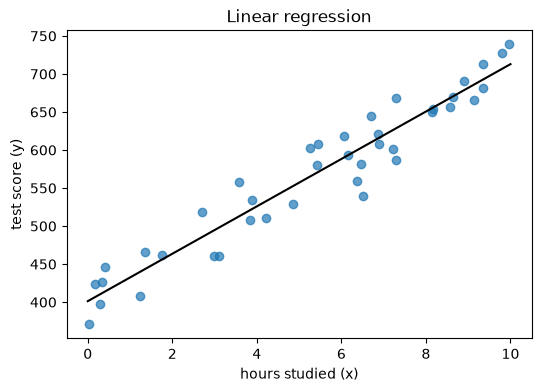

intercept = 401.3, slope = 31.2
Predicted score for 6 hours: 588


In [3]:
from sklearn.linear_model import LinearRegression

rng = np.random.default_rng(0)
hours = rng.uniform(0, 10, size=40)                 # feature x
score = 400 + 30 * hours + rng.normal(0, 25, 40)    # target y (synthetic)

reg = LinearRegression().fit(hours.reshape(-1, 1), score)
line_x = np.array([[0], [10]])

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(hours, score, alpha=0.7)
ax.plot(line_x, reg.predict(line_x), c="k")
ax.set(xlabel="hours studied (x)", ylabel="test score (y)", title="Linear regression")
plt.show()

print(f"intercept = {reg.intercept_:.1f}, slope = {reg.coef_[0]:.1f}")
print(f"Predicted score for 6 hours: {reg.predict([[6]])[0]:.0f}")

#### Companion tutorial: how a model is fit

Before the exercises, work through `machine-learning/supervised-learning/decision-trees/how-models-work.ipynb`. It is lesson 1 of Kaggle's *Intro to Machine Learning* ([How Models Work](https://www.kaggle.com/code/dansbecker/how-models-work), by Dan Becker). It uses a small decision tree that predicts house prices to show what *fitting* and *predicting* mean, which is the supervised workflow of this section with a regression target.

### Exercise 2.1

Fill in the table. For each task say whether it is classification or regression, and what the label or target is.

| Task | Classification or regression? | Label / target |
|---|---|---|
| Decide whether an email is spam | | |
| Estimate the sale price of a house | | |
| Recognize a handwritten digit | | |
| Estimate the delivery time of a meal | | |
| Predict whether a customer cancels a subscription | | |

### Exercise 2.2

In the classification demo, change `cluster_std` to `3.0` and run it again. What happens to the two classes and to the decision boundary? Can a straight line still separate them without mistakes?

In [4]:
# TODO: Exercise 2.2

**Your observations:**

### 2.2 Reinforcement learning

An **agent** interacts with an **environment**. At each step it observes the **state**, chooses an **action** and receives a **reward**. Its goal is to learn the series of actions that maximizes the total reward, by trial and error or by planning.

The reward is not a correct label. It only measures how good the action was, and it can arrive late. In chess the reward (win or lose) comes at the end of the game, after many moves, and it also depends on what the opponent does.

### Exercise 2.3

For a chess program, identify each piece of the loop.

| Element | In chess |
|---|---|
| Agent | |
| Environment | |
| State | |
| Action | |
| Reward | |

Then explain in one or two sentences why delayed reward makes learning harder than in supervised learning.

**Your answer:**

### 2.3 Unsupervised learning

There are no labels and no reward. The algorithm explores the structure of the data on its own.

- **Clustering** organizes examples into groups (clusters) whose members are similar to each other and different from the members of other groups. It is sometimes called unsupervised classification. A typical use is finding customer segments.
- **Dimensionality reduction** compresses data with many features into fewer dimensions while keeping most of the relevant information. It removes noise, saves storage and compute, and lets you plot high-dimensional data in 2D or 3D.

#### Demo: clustering

The algorithm receives the points on the left, with no labels. It returns the grouping on the right.

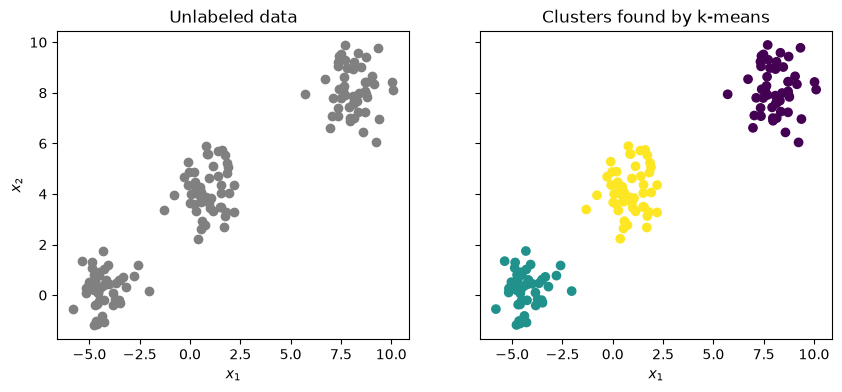

In [5]:
from sklearn.cluster import KMeans

X_blobs, _ = make_blobs(n_samples=150, centers=3, cluster_std=0.8, random_state=3)  # labels discarded
clusters = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(X_blobs)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
axes[0].scatter(*X_blobs.T, c="gray")
axes[0].set(title="Unlabeled data", xlabel="$x_1$", ylabel="$x_2$")
axes[1].scatter(*X_blobs.T, c=clusters, cmap="viridis")
axes[1].set(title="Clusters found by k-means", xlabel="$x_1$")
plt.show()

#### Demo: dimensionality reduction

A Swiss roll is a 2D sheet rolled up in 3D. A nonlinear method (here locally linear embedding) unrolls it onto a 2D plane. The color shows the position along the roll, so you can check that neighbors stay neighbors.

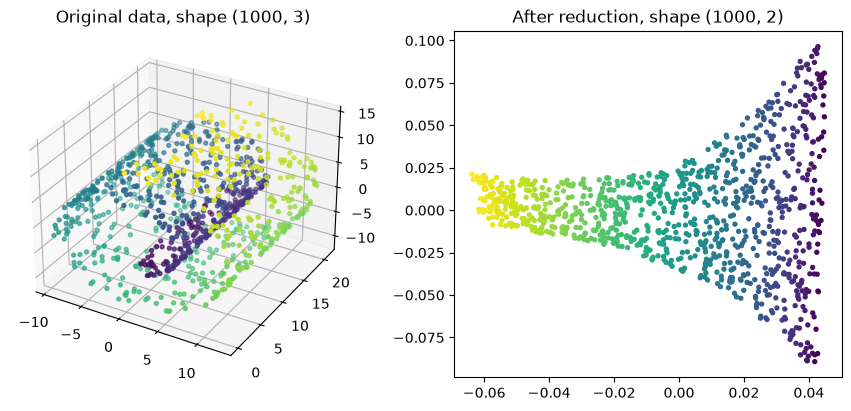

In [6]:
from sklearn.datasets import make_swiss_roll
from sklearn.manifold import LocallyLinearEmbedding

X_roll, position = make_swiss_roll(n_samples=1000, random_state=0)
X_flat = LocallyLinearEmbedding(n_neighbors=12, n_components=2, random_state=0).fit_transform(X_roll)

fig = plt.figure(figsize=(11, 4.5))
ax3d = fig.add_subplot(1, 2, 1, projection="3d")
ax3d.scatter(*X_roll.T, c=position, cmap="viridis", s=8)
ax3d.set_title(f"Original data, shape {X_roll.shape}")
ax2d = fig.add_subplot(1, 2, 2)
ax2d.scatter(*X_flat.T, c=position, cmap="viridis", s=8)
ax2d.set_title(f"After reduction, shape {X_flat.shape}")
plt.show()

### Exercise 2.4

1. Run k-means on `X_blobs` with `n_clusters=2` and with `n_clusters=5` and plot both results. The algorithm always returns the number of clusters you ask for. How would you decide which number is right when you have no labels?
2. Reduce the Iris features (4 dimensions) to 2 with `sklearn.decomposition.PCA` and draw a scatter plot colored by species. Do the species separate?

In [7]:
# TODO: Exercise 2.4, part 1

In [8]:
# TODO: Exercise 2.4, part 2

**Your observations:**

## 3. Terminology and notation

### The Iris dataset as a matrix

Iris has 150 flowers from three species (Setosa, Versicolor, Virginica) and four measurements per flower in centimeters. Each flower is a row and each measurement is a column, so the dataset is a $150 \times 4$ feature matrix:

$$
\boldsymbol{X} \in \mathbb{R}^{150 \times 4}, \qquad
\boldsymbol{X} =
\begin{bmatrix}
x_1^{(1)} & x_2^{(1)} & x_3^{(1)} & x_4^{(1)} \\
x_1^{(2)} & x_2^{(2)} & x_3^{(2)} & x_4^{(2)} \\
\vdots & \vdots & \vdots & \vdots \\
x_1^{(150)} & x_2^{(150)} & x_3^{(150)} & x_4^{(150)}
\end{bmatrix}
$$

Conventions used in this path:

- The **superscript** $(i)$ is the training example (row). The **subscript** $j$ is the feature (column). So $x_1^{(150)}$ is the first feature, sepal length, of flower 150.
- Lowercase bold letters are vectors ($\boldsymbol{x}$). Uppercase bold letters are matrices ($\boldsymbol{X}$). Italic letters are single elements.
- Each row is a row vector $\boldsymbol{x}^{(i)} \in \mathbb{R}^{1 \times 4}$. Each column is a column vector $\boldsymbol{x}_j \in \mathbb{R}^{150 \times 1}$.
- The targets form a column vector $\boldsymbol{y}$ with $y^{(i)} \in \{\text{Setosa}, \text{Versicolor}, \text{Virginica}\}$.

**Watch out:** `machine-learning/supervised-learning/introduction.ipynb` in this repo writes the matrix the other way around, with the subscript for the example and the superscript for the feature ($x_1^{(p)}$ is feature $p$ of example 1). The convention above is the common one in machine learning texts, and the rest of this learning path uses it.

Python counts from 0, so $x_j^{(i)}$ is `X[i - 1, j - 1]`.

In [9]:
from sklearn.datasets import load_iris

iris = load_iris()
X, y = iris.data, iris.target

print("X.shape:", X.shape, "-> 150 examples (rows), 4 features (columns)")
print("y.shape:", y.shape)
print("features:", iris.feature_names)
print("classes: ", [str(name) for name in iris.target_names])
print()
print("x^(150)_1 = X[149, 0] =", X[149, 0], "(sepal length of flower 150)")
print("row vector x^(1)      =", X[0], "shape", X[0:1].shape)
print("column vector x_1 has shape", X[:, 0:1].shape)

pd.DataFrame(X, columns=iris.feature_names).assign(species=iris.target_names[y]).head()

X.shape: (150, 4) -> 150 examples (rows), 4 features (columns)
y.shape: (150,)
features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
classes:  ['setosa', 'versicolor', 'virginica']

x^(150)_1 = X[149, 0] = 5.9 (sepal length of flower 150)
row vector x^(1)      = [5.1 3.5 1.4 0.2] shape (1, 4)
column vector x_1 has shape (150, 1)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### Synonyms you will meet

| Term | Also called |
|---|---|
| Training example | Observation, record, instance, sample (a row of the table) |
| Training | Model fitting; for parametric models, parameter estimation |
| Feature, $x$ | Predictor, variable, input, attribute, covariate (a column of the table) |
| Target, $y$ | Outcome, output, response variable, dependent variable, (class) label, ground truth |
| Loss function | Cost function, error function. Some texts use *loss* for one data point and *cost* for the whole dataset |

### Exercise 3.1

Using `X` and `y` from the cell above:

1. Print $x_3^{(42)}$. Which measurement is it?
2. Extract the column vector $\boldsymbol{x}_2$ so that its shape is `(150, 1)`, not `(150,)`.
3. Count how many flowers belong to each species.

In [10]:
# TODO: Exercise 3.1

### Exercise 3.2

The salary dataset in `machine-learning/supervised-learning/linear-regression/data/salary_data.csv` has two columns. Load it and say, in the vocabulary of this section: how many training examples are there, which column is the feature, which is the target, and what the shapes of $\boldsymbol{X}$ and $\boldsymbol{y}$ are.

In [11]:
# TODO: Exercise 3.2

**Your answer:**

## 4. A roadmap for building machine learning systems

The learning algorithm is one part of a larger workflow:

1. **Preprocessing.** Raw data rarely arrives in the shape an algorithm needs. You extract and select features, put them on the same scale (a $[0, 1]$ range, or zero mean and unit variance), and sometimes reduce dimensionality when features are correlated or noisy.
2. **Train and test split.** You randomly split the data. The training set fits and tunes the model. The test set stays untouched until the end.
3. **Training and model selection.** No algorithm is best for every problem (Wolpert's *no free lunch* theorems), so you compare several. To compare you need a metric, for example accuracy, the proportion of correctly classified examples. **Cross-validation** splits the training data again into training and validation parts, so you can estimate performance without touching the test set. **Hyperparameters** are the settings the algorithm does not learn from the data, and you tune them with the same technique.
4. **Evaluation and prediction.** The test set gives the estimate of the generalization error. If it is good enough, the model predicts new data.

One rule runs through all the steps: the parameters of every preprocessing step (the mean and standard deviation for scaling, for example) come from the training set only. You reuse those same parameters on the test set and on new data. Otherwise the test score comes out too optimistic.

### Demo: the baseline pipeline on Iris

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 2) Split first. stratify=y keeps the class proportions in both parts.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1, stratify=y)
print("train:", X_train.shape, "test:", X_test.shape)

# 1) Preprocessing: the scaler learns mean and std from the training set only
scaler = StandardScaler().fit(X_train)
X_train_std = scaler.transform(X_train)
X_test_std = scaler.transform(X_test)      # same parameters, reused
print("means learned from train:", scaler.mean_.round(2))

# 3) Train one model. n_neighbors is a hyperparameter.
knn = KNeighborsClassifier(n_neighbors=5).fit(X_train_std, y_train)

# 4) Evaluate on the test set
y_pred = knn.predict(X_test_std)
print(f"test accuracy: {accuracy_score(y_test, y_pred):.3f} "
      f"({(y_test == y_pred).sum()} of {len(y_test)} correct)")

train: (105, 4) test: (45, 4)
means learned from train: [5.86 3.07 3.79 1.2 ]
test accuracy: 0.933 (42 of 45 correct)


### Exercise 4.1: compare models with cross-validation

Use `sklearn.model_selection.cross_val_score` with `cv=5` on the **training** data to compare three classifiers: `KNeighborsClassifier`, `LogisticRegression` and `DecisionTreeClassifier`. Report the mean and standard deviation of the accuracy for each. Which would you pick? Is the difference larger than the spread between folds?

Hint: wrap the scaler and the model with `sklearn.pipeline.make_pipeline` so the scaler is refit inside each fold.

In [13]:
# TODO: Exercise 4.1

### Exercise 4.2: tune a hyperparameter

For k-nearest neighbors, try `n_neighbors` from 1 to 20 with 5-fold cross-validation on the training data. Plot the mean accuracy against `n_neighbors` and pick a value. Only then evaluate that final model on the test set, once.

In [14]:
# TODO: Exercise 4.2

### Exercise 4.3: find the leak

This snippet scales the data before splitting it:

```python
X_std = StandardScaler().fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_std, y, test_size=0.3)
```

What is wrong with it, according to the rule in the roadmap? Which numbers did the test set contribute to?

### Exercise 4.4: why keep a test set at all?

If cross-validation already estimates performance, why keep a separate test set until the very end? Answer in two or three sentences.

**Your answers:**

## 5. Using Python for machine learning

The path uses Python 3 with NumPy, SciPy, scikit-learn, Matplotlib and pandas. PyTorch comes later, with the deep learning modules, so there is no need to install it yet. The first cell of this notebook prints your versions. Newer versions sometimes break older code, so check versions first when an example copied from a book or tutorial fails.

Commands you will need:

```bash
python --version                       # check the interpreter

pip install SomePackage                # install with pip
pip install SomePackage --upgrade

conda install SomePackage              # install with conda
conda update SomePackage
conda install SomePackage --channel conda-forge

python3 -m venv ~/envs/ml-path       # virtual environment with venv
source ~/envs/ml-path/bin/activate

conda create -n pyml python=3.9        # virtual environment with conda
conda activate pyml
```

Conda comes in three flavors: Anaconda (many packages preinstalled), Miniconda (no packages preinstalled) and Miniforge (community-maintained, uses conda-forge).

### Exercise 5.1

Create a dedicated environment for this repository (conda or venv), install the five packages plus `jupyter`, and select it as the kernel for this notebook. Run the first cell again and confirm the versions.

### Exercise 5.2

This repository has no `requirements.txt` or `environment.yml`. Add one that pins the versions you installed, so the notebooks keep running later.

## 6. Self-check

Answer without looking at the notes. If one costs you, go back to that section.

1. What is the difference between supervised and unsupervised learning?
2. What separates classification from regression? Give one example of each.
3. Why can a digit classifier trained only on letters not recognize a 7?
4. In reinforcement learning, how does a reward differ from a label?
5. Give two reasons to reduce the dimensionality of a dataset.
6. In the notation of section 3, what is $x_2^{(7)}$? What are the shapes of $\boldsymbol{x}^{(7)}$ and $\boldsymbol{x}_2$ for Iris?
7. What is a hyperparameter, and how is it different from a parameter the model learns?
8. Why must scaling parameters come from the training set only?

**Your answers:**

## Next

The next module covers the first classifiers: the perceptron and adaptive linear neurons, trained with gradient descent. This repo already has a perceptron notebook at `machine-learning/supervised-learning/perceptron/neuron-perceptron.ipynb`. The learning path in `machine-learning/learning-path/README.md` tracks what is covered.